# Hypothesis Analysis — Breast Cancer Care in Brazil's North Region

## Purpose and connection to the business problem

Daiichi Sankyo's project seeks to estimate potential demand generated by health-insurance operators and allocated to specialized healthcare services. This notebook formulates and tests exactly three exploratory hypotheses about demand concentration across health plans, geographic displacement, and demographic/geographic differences in the 2025 North-region TISS data. The analysis uses the treated breast-cancer-scope dataset produced by the project's preprocessing pipeline.

This notebook is responsible only for hypothesis formulation and analysis. It receives the processed Parquet dataset produced by the project's ingestion and preprocessing notebooks as an input and does not repeat, replace, or evaluate their data-treatment decisions. It does not alter or export the source data. The only operations performed here are analytical selections, event-level aggregation, visualization, and quantitative evaluation required by the three hypotheses.

### Analytical safeguards

- TISS is an administrative billing source, not a cancer registry.
- A dataset row is a billed item/record; it is not necessarily a unique patient or a unique healthcare event.
- `ID_EVENTO_ATENCAO_SAUDE` is therefore used to construct event-level tables when the hypothesis refers to events.
- Missing measurements are never replaced with zero because missing and observed zero values have different meanings.
- Statistical significance is interpreted together with effect size and sample size. With a large dataset, a small difference can have a very small p-value without being operationally important.
- Results are associations and do not establish causality, confirmed diagnosis, prevalence, or treatment eligibility.

## 1. Input and reproducible loading

**Upstream:** `04_data_treatment.ipynb`. **Required input:** `data/processed/north_region_mama_2025_data_en.parquet`. **Output:** in-notebook hypothesis results only; no pipeline artifact is generated. **Downstream:** none. Notebooks 05 and 06 independently read the same canonical output from notebook 04.

The processed dataset is the formal input of this notebook. The first code cell installs only libraries required to load and analyze that input when they are absent. The path resolver supports execution from the repository root or from `notebooks/`. If the processed Parquet file is absent, notebook 04 must be executed first.

In [1]:
import importlib.util
import subprocess
import sys

required_packages = {
    "numpy": "numpy>=1.26,<3",
    "pandas": "pandas>=2.2,<4",
    "pyarrow": "pyarrow>=18",
    "matplotlib": "matplotlib>=3.8,<4",
}
missing_packages = [
    requirement for module, requirement in required_packages.items()
    if importlib.util.find_spec(module) is None
]
if missing_packages:
    print("Installing missing packages:", ", ".join(missing_packages))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing_packages])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

plt.style.use("default")
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "font.size": 10,
})

WORKING_DIR = Path.cwd().resolve()
REPO_ROOT = WORKING_DIR.parent if WORKING_DIR.name == "notebooks" else WORKING_DIR
data_path = REPO_ROOT / "data" / "processed" / "north_region_mama_2025_data_en.parquet"
if not data_path.is_file():
    raise FileNotFoundError(
        "Missing treated dataset. Run 04_data_treatment.ipynb first. "
        f"Expected path: {data_path}"
    )

required_columns = [
    "ID_EVENTO_ATENCAO_SAUDE", "ID_PLANO", "PORTE",
    "CD_MUNICIPIO_BENEFICIARIO",
    "CD_MUNICIPIO_PRESTADOR", "UF_PRESTADOR",
    "FAIXA_ETARIA", "IND_HIGH_SPECIFICITY_PROXY",
]
df = pd.read_parquet(data_path, columns=required_columns)
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise KeyError(f"Required columns are missing: {missing_columns}")

print(f"Loaded {len(df):,} billed records from {data_path}")
print(f"Unique healthcare-event IDs: {df['ID_EVENTO_ATENCAO_SAUDE'].nunique():,}")
print(f"Provider states: {df['UF_PRESTADOR'].nunique()}")

Loaded 310,340 billed records from data\processed\north_region_mama_2025_data_en.parquet
Unique healthcare-event IDs: 291,864
Provider states: 7


## 2. Hypothesis 1 — Concentration of observed demand across health plans

### Formulation

**H1:** Observed breast-cancer-related service demand is concentrated in a small subset of health plans, and operator size alone is insufficient to explain the variation in demand between plans.

**Reference scenario (H1₀):** Healthcare events are distributed approximately proportionally across plans, without strong concentration in a small group, and plans within the same operator-size category have broadly similar observed volumes.

### Rationale and variables

The partner needs to identify where potential demand is generated in order to prioritize operators, plans, regions, and specialized services. If most observed breast-cancer-related activity is generated by a relatively small group of plans, an aggregate estimate by operator-size category can hide the plans that account for most service potential. Conversely, if plans classified under the same `PORTE` category still present very different volumes, size should be treated as contextual information rather than as a sufficient demand-ranking rule.

Variables: `ID_EVENTO_ATENCAO_SAUDE`, `ID_PLANO`, and `PORTE`. `ID_PLANO` identifies a health plan rather than a corporate operator; one operator may therefore be represented by more than one plan. The result is deliberately interpreted at plan level.

### Decision: event-level demand proxy and concentration measures

A billed record is not equivalent to a patient, and one healthcare event may contain several billed-item rows. The analysis therefore retains one row per `ID_EVENTO_ATENCAO_SAUDE` before counting demand by plan. The code verifies that a single event is not assigned to conflicting plans or size categories. Concentration is summarized through cumulative shares, top-plan shares, and the Gini coefficient; values closer to one indicate stronger concentration. These measures describe observed administrative service demand, not unique patients or unmet epidemiological demand.

In [3]:
h1_source = df[[
    "ID_EVENTO_ATENCAO_SAUDE", "ID_PLANO", "PORTE",
]].copy()

event_consistency = h1_source.groupby("ID_EVENTO_ATENCAO_SAUDE", observed=True).agg({
    "ID_PLANO": "nunique",
    "PORTE": "nunique",
})
conflicting_events = event_consistency.gt(1).any(axis=1).sum()
print(f"Events assigned to conflicting plans or size categories: {conflicting_events:,}")

h1_events = (
    h1_source.groupby("ID_EVENTO_ATENCAO_SAUDE", as_index=False, observed=True)
             .agg(
                 ID_PLANO=("ID_PLANO", "first"),
                 PORTE=("PORTE", "first"),
             )
             .dropna(subset=["ID_PLANO", "PORTE"])
)
plan_size_consistency = h1_events.groupby("ID_PLANO", observed=True)["PORTE"].nunique()
print(f"Plans assigned to more than one size category: {(plan_size_consistency > 1).sum():,}")

h1_plans = (
    h1_events.groupby(["ID_PLANO", "PORTE"], as_index=False, observed=True)
             .agg(
                 unique_events=("ID_EVENTO_ATENCAO_SAUDE", "nunique"),
             )
)

def concentration_share(values, fraction):
    ordered = pd.Series(values).sort_values(ascending=False).reset_index(drop=True)
    selected = max(1, int(np.ceil(len(ordered) * fraction)))
    return ordered.iloc[:selected].sum() / ordered.sum()

def gini_coefficient(values):
    ordered = np.sort(np.asarray(values, dtype=float))
    if len(ordered) == 0 or ordered.sum() == 0:
        return np.nan
    ranks = np.arange(1, len(ordered) + 1)
    return (2 * np.sum(ranks * ordered) / (len(ordered) * ordered.sum())) - (len(ordered) + 1) / len(ordered)

top_1_share = concentration_share(h1_plans["unique_events"], 0.01)
top_10_share = concentration_share(h1_plans["unique_events"], 0.10)
top_20_share = concentration_share(h1_plans["unique_events"], 0.20)
event_gini = gini_coefficient(h1_plans["unique_events"])

print(f"Health plans analyzed: {len(h1_plans):,}")
print(f"Unique healthcare events: {h1_plans['unique_events'].sum():,}")
print(f"Top 1% of plans — event share: {top_1_share:.1%}")
print(f"Top 10% of plans — event share: {top_10_share:.1%}")
print(f"Top 20% of plans — event share: {top_20_share:.1%}")
print(f"Gini coefficient of events per plan: {event_gini:.3f}")

Events assigned to conflicting plans or size categories: 0


Plans assigned to more than one size category: 0


Health plans analyzed: 3,289
Unique healthcare events: 291,864
Top 1% of plans — event share: 41.7%
Top 10% of plans — event share: 84.2%
Top 20% of plans — event share: 92.9%
Gini coefficient of events per plan: 0.888


,plans,total_events,mean_events_per_plan,median_events_per_plan,top_10_percent_event_share
PORTE,,,,,
GRANDE,2266,228373,100.8,6.0,88.0%
MÉDIO,680,50527,74.3,7.0,70.2%
PEQUENO,287,11851,41.3,8.0,61.6%
SEM BENEFICIÁRIOS,56,1113,19.9,3.0,57.8%


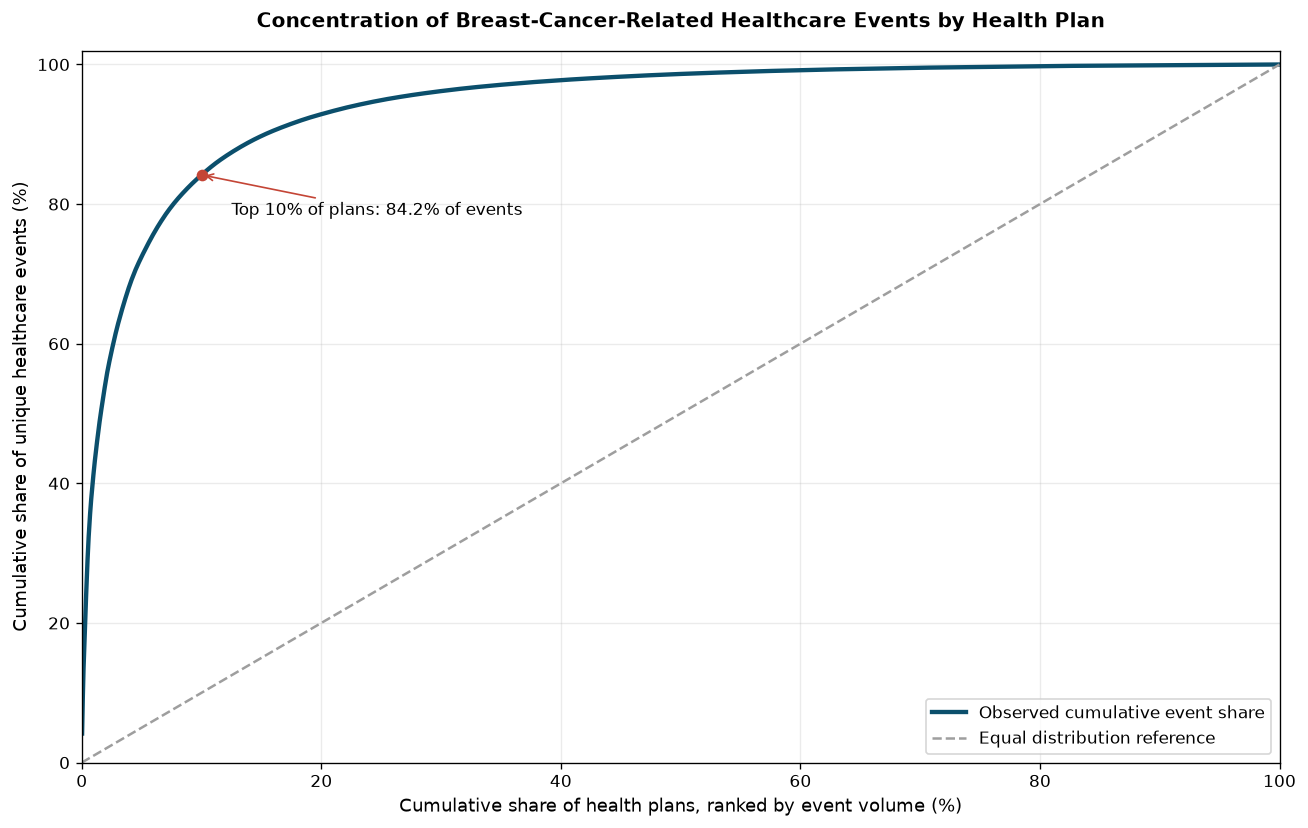

In [4]:
ranked_plans = h1_plans.sort_values("unique_events", ascending=False).reset_index(drop=True).copy()
ranked_plans["cumulative_plan_share"] = 100 * (np.arange(len(ranked_plans)) + 1) / len(ranked_plans)
ranked_plans["cumulative_event_share"] = 100 * ranked_plans["unique_events"].cumsum() / ranked_plans["unique_events"].sum()

porte_summary = (
    h1_plans.groupby("PORTE", observed=True)
            .agg(
                plans=("ID_PLANO", "nunique"),
                total_events=("unique_events", "sum"),
                mean_events_per_plan=("unique_events", "mean"),
                median_events_per_plan=("unique_events", "median"),
            )
)
porte_top_10 = h1_plans.groupby("PORTE", observed=True).apply(
    lambda group: concentration_share(group["unique_events"], 0.10),
    include_groups=False,
).rename("top_10_percent_event_share")
porte_summary = porte_summary.join(porte_top_10).sort_values("total_events", ascending=False)
porte_display = porte_summary.copy()
porte_display["mean_events_per_plan"] = porte_display["mean_events_per_plan"].round(1)
porte_display["median_events_per_plan"] = porte_display["median_events_per_plan"].round(1)
porte_display["top_10_percent_event_share"] = porte_display["top_10_percent_event_share"].map(lambda value: f"{value:.1%}")
display(porte_display)

fig, ax = plt.subplots(figsize=(11, 7))
ax.plot(
    ranked_plans["cumulative_plan_share"], ranked_plans["cumulative_event_share"],
    color="#0B4F6C", linewidth=2.6, label="Observed cumulative event share",
)
ax.plot([0, 100], [0, 100], color="#9E9E9E", linestyle="--", label="Equal distribution reference")
ax.scatter([10], [100 * top_10_share], color="#C44536", zorder=3)
ax.annotate(
    f"Top 10% of plans: {top_10_share:.1%} of events",
    (10, 100 * top_10_share), xytext=(18, -24), textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#C44536"},
)
ax.set_title("Concentration of Breast-Cancer-Related Healthcare Events by Health Plan", pad=14)
ax.set_xlabel("Cumulative share of health plans, ranked by event volume (%)")
ax.set_ylabel("Cumulative share of unique healthcare events (%)")
ax.set_xlim(0, 100)
ax.set_ylim(0, 102)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

### Interpretation rule

H1 is supported if a small share of plans accounts for a large share of unique events, the cumulative curve lies substantially above the equal-distribution line, and the Gini coefficient indicates strong concentration. The second part of H1 is supported when event volumes remain highly concentrated within `PORTE` categories and central-tendency measures do not provide one simple, stable ordering of plan-level demand. Mean and median must be read together because a few extremely high-volume plans can raise the mean while most plans remain small.

The analysis supports prioritization and feature design, but it does not prove that a plan has more unique patients: repeated healthcare events may belong to the same beneficiary, and no patient identifier is available. It also does not estimate unmet demand outside the supplementary-health records. `SEM BENEFICIÁRIOS` is retained for transparency but must be interpreted cautiously because it reflects the upstream operator-size classification rather than absence of billed activity in this dataset.

## 3. Hypothesis 2 — Intermunicipal displacement for care

### Formulation

**H2:** The proportion of healthcare events delivered outside the beneficiary's municipality of residence differs across provider states in Brazil's North region, indicating territorial differences in the spatial distribution of the specialized care network.

**Null hypothesis (H2₀):** Intermunicipal displacement status is independent of provider state.

### Rationale and variables

The business problem requires allocating operator-generated demand to specialized services. If care frequently occurs outside the beneficiary's municipality, residence alone is not enough to infer where service potential materializes. Comparing municipalities of residence and care provides a direct administrative indicator of geographic flow.

Variables: `ID_EVENTO_ATENCAO_SAUDE`, `CD_MUNICIPIO_BENEFICIARIO`, `CD_MUNICIPIO_PRESTADOR`, and `UF_PRESTADOR`.

### Decision: conservative operational definition

An event is classified as intermunicipal when both municipality codes are present and different. This is called **recorded intermunicipal displacement**, not formal *Tratamento Fora de Domicílio* (TFD): the data do not reveal the administrative reason, distance traveled, network authorization, or whether two municipalities belong to the same metropolitan area. Events missing either municipality are reported and excluded from the rate denominator. One row per event is retained to avoid weighting events by their number of billed items.

In [5]:
h2_source = df[[
    "ID_EVENTO_ATENCAO_SAUDE", "CD_MUNICIPIO_BENEFICIARIO",
    "CD_MUNICIPIO_PRESTADOR", "UF_PRESTADOR"
]].copy()

h2_conflicts = h2_source.groupby("ID_EVENTO_ATENCAO_SAUDE").agg({
    "CD_MUNICIPIO_BENEFICIARIO": "nunique",
    "CD_MUNICIPIO_PRESTADOR": "nunique",
    "UF_PRESTADOR": "nunique",
})
conflicting_events = h2_conflicts.gt(1).any(axis=1).sum()
print(f"Events with conflicting geographic values across item rows: {conflicting_events:,}")

h2_events = h2_source.drop_duplicates(subset="ID_EVENTO_ATENCAO_SAUDE", keep="first").copy()
complete_geo = h2_events.dropna(subset=[
    "CD_MUNICIPIO_BENEFICIARIO", "CD_MUNICIPIO_PRESTADOR", "UF_PRESTADOR"
]).copy()
complete_geo["INTERMUNICIPAL_DISPLACEMENT"] = (
    complete_geo["CD_MUNICIPIO_BENEFICIARIO"].astype(str)
    != complete_geo["CD_MUNICIPIO_PRESTADOR"].astype(str)
)

excluded_geo = len(h2_events) - len(complete_geo)
print(f"Unique events: {len(h2_events):,}")
print(f"Events excluded because geography is incomplete: {excluded_geo:,}")
print(f"Overall recorded intermunicipal displacement: {complete_geo['INTERMUNICIPAL_DISPLACEMENT'].mean():.1%}")

h2_summary = (
    complete_geo.groupby("UF_PRESTADOR", observed=True)["INTERMUNICIPAL_DISPLACEMENT"]
                .agg(displacement_rate="mean", events="size", displaced_events="sum")
                .reset_index()
                .sort_values("displacement_rate", ascending=False)
)
h2_display = h2_summary.copy()
h2_display["displacement_rate"] = h2_display["displacement_rate"].map(lambda value: f"{value:.1%}")
display(h2_display)

Events with conflicting geographic values across item rows: 0


Unique events: 291,864
Events excluded because geography is incomplete: 0
Overall recorded intermunicipal displacement: 26.8%


,UF_PRESTADOR,displacement_rate,events,displaced_events
6,TO,33.1%,20456,6763
3,PA,31.8%,151013,47993
4,RO,22.6%,25315,5715
2,AP,20.4%,13967,2848
1,AM,19.8%,70620,13955
0,AC,12.9%,5198,669
5,RR,7.1%,5295,377


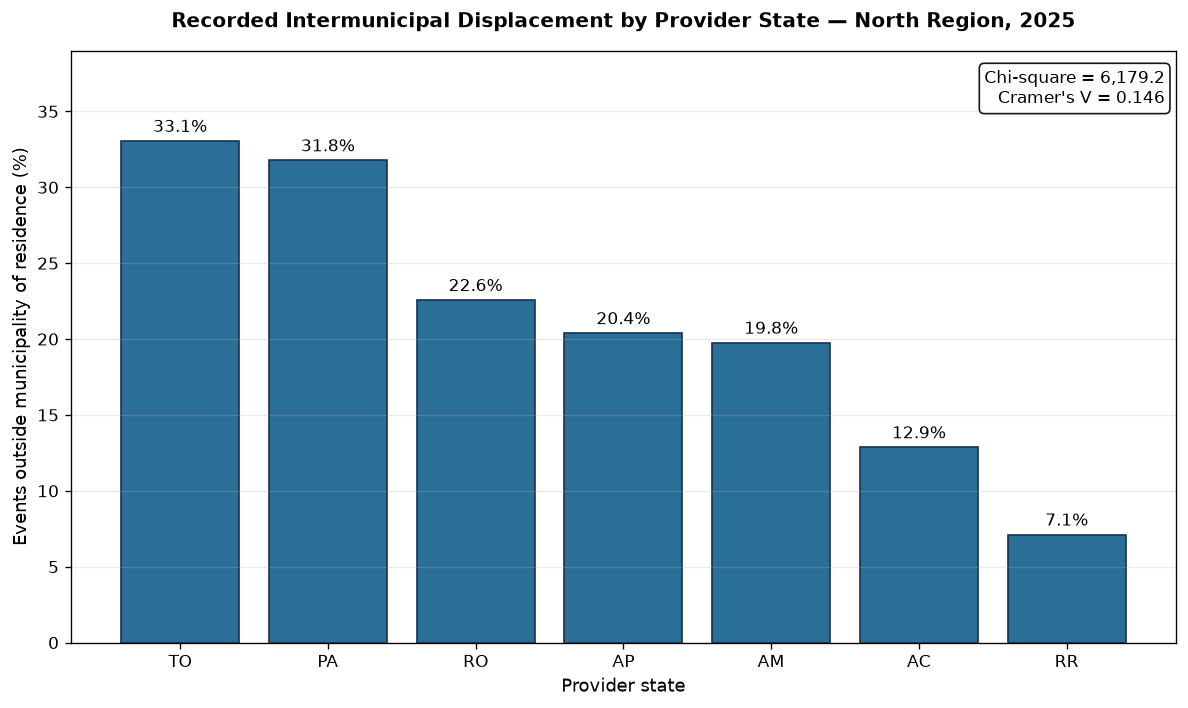

Chi-square = 6,179.24, df = 6
Cramer's V = 0.146


In [6]:
contingency_h2 = pd.crosstab(
    complete_geo["UF_PRESTADOR"], complete_geo["INTERMUNICIPAL_DISPLACEMENT"]
)
observed_h2 = contingency_h2.to_numpy(dtype=float)
expected_h2 = np.outer(observed_h2.sum(axis=1), observed_h2.sum(axis=0)) / observed_h2.sum()
chi2_h2 = np.where(expected_h2 > 0, (observed_h2 - expected_h2) ** 2 / expected_h2, 0).sum()
dof_h2 = (observed_h2.shape[0] - 1) * (observed_h2.shape[1] - 1)
n_h2 = contingency_h2.to_numpy().sum()
cramers_v_h2 = np.sqrt(chi2_h2 / (n_h2 * min(contingency_h2.shape[0] - 1, contingency_h2.shape[1] - 1)))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    h2_summary["UF_PRESTADOR"].astype(str),
    100 * h2_summary["displacement_rate"],
    color="#2A6F97", edgecolor="#16324F",
)
ax.bar_label(bars, labels=[f"{value:.1%}" for value in h2_summary["displacement_rate"]], padding=3)
ax.set_title("Recorded Intermunicipal Displacement by Provider State — North Region, 2025", pad=14)
ax.set_xlabel("Provider state")
ax.set_ylabel("Events outside municipality of residence (%)")
ax.set_ylim(0, max(5, 100 * h2_summary["displacement_rate"].max() * 1.18))
ax.grid(axis="y", alpha=0.25)
ax.text(
    0.99, 0.97, f"Chi-square = {chi2_h2:,.1f}\nCramer's V = {cramers_v_h2:.3f}",
    transform=ax.transAxes, ha="right", va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9},
)
fig.tight_layout()
plt.show()

print(f"Chi-square = {chi2_h2:,.2f}, df = {dof_h2}")
print(f"Cramer's V = {cramers_v_h2:.3f}")

### Interpretation rule

H2 is supported when state rates differ by a meaningful amount and Cramer's V indicates a non-negligible association. The chi-square statistic is reported as a descriptive departure from independence; effect size and the visible percentage-point gaps drive the substantive interpretation. State comparisons describe provider-state patterns in the observed supplementary-health records; they do not measure physical distance, prove lack of access, identify formal TFD cases, or represent people outside private health insurance.

## 4. Hypothesis 3 — Interaction between age and geography

### Formulation

**H3:** The share of healthcare events containing at least one high-specificity breast-cancer proxy item increases across adult age groups, but the magnitude of this pattern differs among provider states in Brazil's North region.

**Null hypotheses (H3₀):** High-specificity event status is independent of adult age group, and within a given age group it is independent of provider state.

### Rationale and variables

Age and geography are explicitly relevant to the project's objective of estimating service potential by patient profile and region. The engineered `IND_HIGH_SPECIFICITY_PROXY` identifies billed records whose TUSS/SBOC mapping provides stronger evidence of the breast-cancer scope than general oncology items. Testing age jointly with state can reveal whether one common age pattern is adequate or whether future models should include an age-by-state interaction or use tree-based algorithms capable of learning non-additive effects.

Variables: `ID_EVENTO_ATENCAO_SAUDE`, `FAIXA_ETARIA`, `UF_PRESTADOR`, and `IND_HIGH_SPECIFICITY_PROXY`.

### Decision: event-level proxy and adult age groups

An event is flagged when at least one of its billed-item rows has `IND_HIGH_SPECIFICITY_PROXY = 1`. Age group and provider state are retained once per event. The chart begins at age 20 because the hypothesis concerns the adult breast-cancer service pathway. Cell denominators are displayed so that unstable percentages from small groups remain visible. Because an event is flagged whenever any single one of its item rows carries the proxy, these event-level rates sit at or above the record-level rates that notebook 06 reports for the same age brackets (23.2% against 21.2% for the 80+ group, for example). The gap is the unit of analysis, not a disagreement between the two notebooks.

In [7]:
adult_age_order = [
    "20 a 29 anos", "30 a 39 anos", "40 a 49 anos",
    "50 a 59 anos", "60 a 69 anos", "70 a 79 anos",
    "80 anos ou mais",
]

h3_source = df[[
    "ID_EVENTO_ATENCAO_SAUDE", "FAIXA_ETARIA",
    "UF_PRESTADOR", "IND_HIGH_SPECIFICITY_PROXY"
]].copy()
h3_events = (
    h3_source.groupby("ID_EVENTO_ATENCAO_SAUDE", as_index=False)
             .agg(
                 FAIXA_ETARIA=("FAIXA_ETARIA", "first"),
                 UF_PRESTADOR=("UF_PRESTADOR", "first"),
                 HIGH_SPECIFICITY_EVENT=("IND_HIGH_SPECIFICITY_PROXY", "max"),
             )
)
adult_events = h3_events[
    h3_events["FAIXA_ETARIA"].isin(adult_age_order)
].dropna(subset=["UF_PRESTADOR", "HIGH_SPECIFICITY_EVENT"]).copy()
adult_events["FAIXA_ETARIA"] = pd.Categorical(
    adult_events["FAIXA_ETARIA"], categories=adult_age_order, ordered=True
)
state_order = sorted(adult_events["UF_PRESTADOR"].astype(str).unique())

proxy_rate = (
    adult_events.groupby(["UF_PRESTADOR", "FAIXA_ETARIA"], observed=True)
                ["HIGH_SPECIFICITY_EVENT"].mean().mul(100).unstack()
                .reindex(index=state_order, columns=adult_age_order)
)
proxy_n = (
    adult_events.groupby(["UF_PRESTADOR", "FAIXA_ETARIA"], observed=True)
                .size().unstack().reindex(index=state_order, columns=adult_age_order)
)
regional_age_summary = (
    adult_events.groupby("FAIXA_ETARIA", observed=True)["HIGH_SPECIFICITY_EVENT"]
                .agg(rate="mean", events="size").reindex(adult_age_order)
)
regional_age_display = regional_age_summary.copy()
regional_age_display["rate"] = regional_age_display["rate"].map(lambda value: f"{value:.1%}")
display(regional_age_display)

,rate,events
FAIXA_ETARIA,,
20 a 29 anos,0.5%,21166
30 a 39 anos,1.8%,46015
40 a 49 anos,3.2%,97730
50 a 59 anos,5.1%,64019
60 a 69 anos,9.0%,39468
70 a 79 anos,13.8%,18508
80 anos ou mais,23.2%,4958


In [8]:
age_contingency = pd.crosstab(adult_events["FAIXA_ETARIA"], adult_events["HIGH_SPECIFICITY_EVENT"])
observed_age = age_contingency.to_numpy(dtype=float)
expected_age = np.outer(observed_age.sum(axis=1), observed_age.sum(axis=0)) / observed_age.sum()
chi2_age = np.where(expected_age > 0, (observed_age - expected_age) ** 2 / expected_age, 0).sum()
dof_age = (observed_age.shape[0] - 1) * (observed_age.shape[1] - 1)
n_age = age_contingency.to_numpy().sum()
cramers_v_age = np.sqrt(chi2_age / (n_age * min(age_contingency.shape[0] - 1, age_contingency.shape[1] - 1)))


def chi_square_upper_tail(chi_square, degrees_of_freedom):
    """P(X > chi_square) for X ~ chi-square(degrees_of_freedom).

    Regularised upper incomplete gamma Q(a, x) with a = df/2 and x = chi2/2:
    the series expansion below the transition point x < a + 1, the Lentz
    continued fraction above it. Written out here so this notebook keeps the
    four-package dependency set declared in requirements.txt instead of
    pulling in SciPy for a single tail probability. Reproduces the published
    chi-square critical values for df 1-10 at alpha 0.05 and 0.01 to within
    2e-5. Returns 0.0 when the tail underflows double precision.
    """
    a = degrees_of_freedom / 2.0
    x = chi_square / 2.0
    if x <= 0:
        return 1.0
    log_gamma_a = math.lgamma(a)
    if x < a + 1.0:
        term = 1.0 / a
        total = term
        n = a
        for _ in range(1000):
            n += 1.0
            term *= x / n
            total += term
            if abs(term) < abs(total) * 1e-16:
                break
        return 1.0 - total * math.exp(-x + a * math.log(x) - log_gamma_a)
    tiny = 1e-300
    b = x + 1.0 - a
    c = 1.0 / tiny
    d = 1.0 / b
    h = d
    for i in range(1, 1000):
        an = -i * (i - a)
        b += 2.0
        d = an * d + b
        if abs(d) < tiny:
            d = tiny
        c = b + an / c
        if abs(c) < tiny:
            c = tiny
        d = 1.0 / d
        delta = d * c
        h *= delta
        if abs(delta - 1.0) < 1e-16:
            break
    return h * math.exp(-x + a * math.log(x) - log_gamma_a)


def holm_bonferroni(p_values):
    """Holm step-down adjusted p-values for a family of tests, in input order.

    Holm is used rather than plain Bonferroni because it controls the same
    family-wise error rate while rejecting at least as often, so it is the
    less conservative of the two at no cost in guarantees.
    """
    p_values = np.asarray(p_values, dtype=float)
    family_size = p_values.size
    ascending = np.argsort(p_values)
    adjusted = np.empty(family_size)
    running_max = 0.0
    for rank, index in enumerate(ascending):
        running_max = max(running_max, min(1.0, (family_size - rank) * p_values[index]))
        adjusted[index] = running_max
    return adjusted


state_within_age_tests = []
for age_group in adult_age_order:
    age_slice = adult_events[adult_events["FAIXA_ETARIA"] == age_group]
    table = pd.crosstab(age_slice["UF_PRESTADOR"], age_slice["HIGH_SPECIFICITY_EVENT"])
    if table.shape[0] > 1 and table.shape[1] == 2:
        observed = table.to_numpy(dtype=float)
        expected = np.outer(observed.sum(axis=1), observed.sum(axis=0)) / observed.sum()
        chi2 = np.where(expected > 0, (observed - expected) ** 2 / expected, 0).sum()
        dof = (observed.shape[0] - 1) * (observed.shape[1] - 1)
        n = table.to_numpy().sum()
        v = np.sqrt(chi2 / (n * min(table.shape[0] - 1, table.shape[1] - 1)))
        state_within_age_tests.append({
            "age_group": age_group, "events": n, "chi_square": chi2,
            "degrees_of_freedom": dof, "cramers_v": v,
            "p_value": chi_square_upper_tail(chi2, dof),
        })
state_within_age_tests = pd.DataFrame(state_within_age_tests)

# The state-within-age comparison is not a single test: one chi-square is run
# per adult age bracket, so the tests below form one family and their
# significance must be read with that multiplicity in mind.
FAMILY_ALPHA = 0.05
family_size = len(state_within_age_tests)
state_within_age_tests["p_value_holm"] = holm_bonferroni(state_within_age_tests["p_value"])
state_within_age_tests["significant_holm"] = state_within_age_tests["p_value_holm"] < FAMILY_ALPHA

print(f"Age-group association: chi-square = {chi2_age:,.2f}, df = {dof_age}")
print(f"Age-group Cramer's V = {cramers_v_age:.3f}")
print(
    f"\nStratified state-within-age tests: family of {family_size}. "
    f"Bonferroni per-test threshold = {FAMILY_ALPHA / family_size:.5f}; "
    f"reported p-values are Holm-adjusted for the {family_size} comparisons."
)
print(
    f"Tests surviving Holm at alpha = {FAMILY_ALPHA}: "
    f"{int(state_within_age_tests['significant_holm'].sum())} of {family_size}."
)
state_tests_display = state_within_age_tests.copy()
for column in ["chi_square", "cramers_v"]:
    state_tests_display[column] = state_tests_display[column].round(3)
for column in ["p_value", "p_value_holm"]:
    state_tests_display[column] = state_tests_display[column].map(lambda value: f"{value:.3e}")
display(state_tests_display)

Age-group association: chi-square = 10,280.17, df = 6
Age-group Cramer's V = 0.188

Stratified state-within-age tests: family of 7. Bonferroni per-test threshold = 0.00714; reported p-values are Holm-adjusted for the 7 comparisons.
Tests surviving Holm at alpha = 0.05: 7 of 7.


,age_group,events,chi_square,degrees_of_freedom,cramers_v,p_value,p_value_holm,significant_holm
0,20 a 29 anos,21166,215.184,6,0.101,1.107e-43,1.107e-43,True
1,30 a 39 anos,46015,548.783,6,0.109,2.584e-115,7.751e-115,True
2,40 a 49 anos,97730,1858.645,6,0.138,0.000e+00,0.000e+00,True
3,50 a 59 anos,64019,1698.807,6,0.163,0.000e+00,0.000e+00,True
4,60 a 69 anos,39468,2544.901,6,0.254,0.000e+00,0.000e+00,True
5,70 a 79 anos,18508,2003.852,6,0.329,0.000e+00,0.000e+00,True
6,80 anos ou mais,4958,498.767,6,0.317,1.550e-104,3.100e-104,True


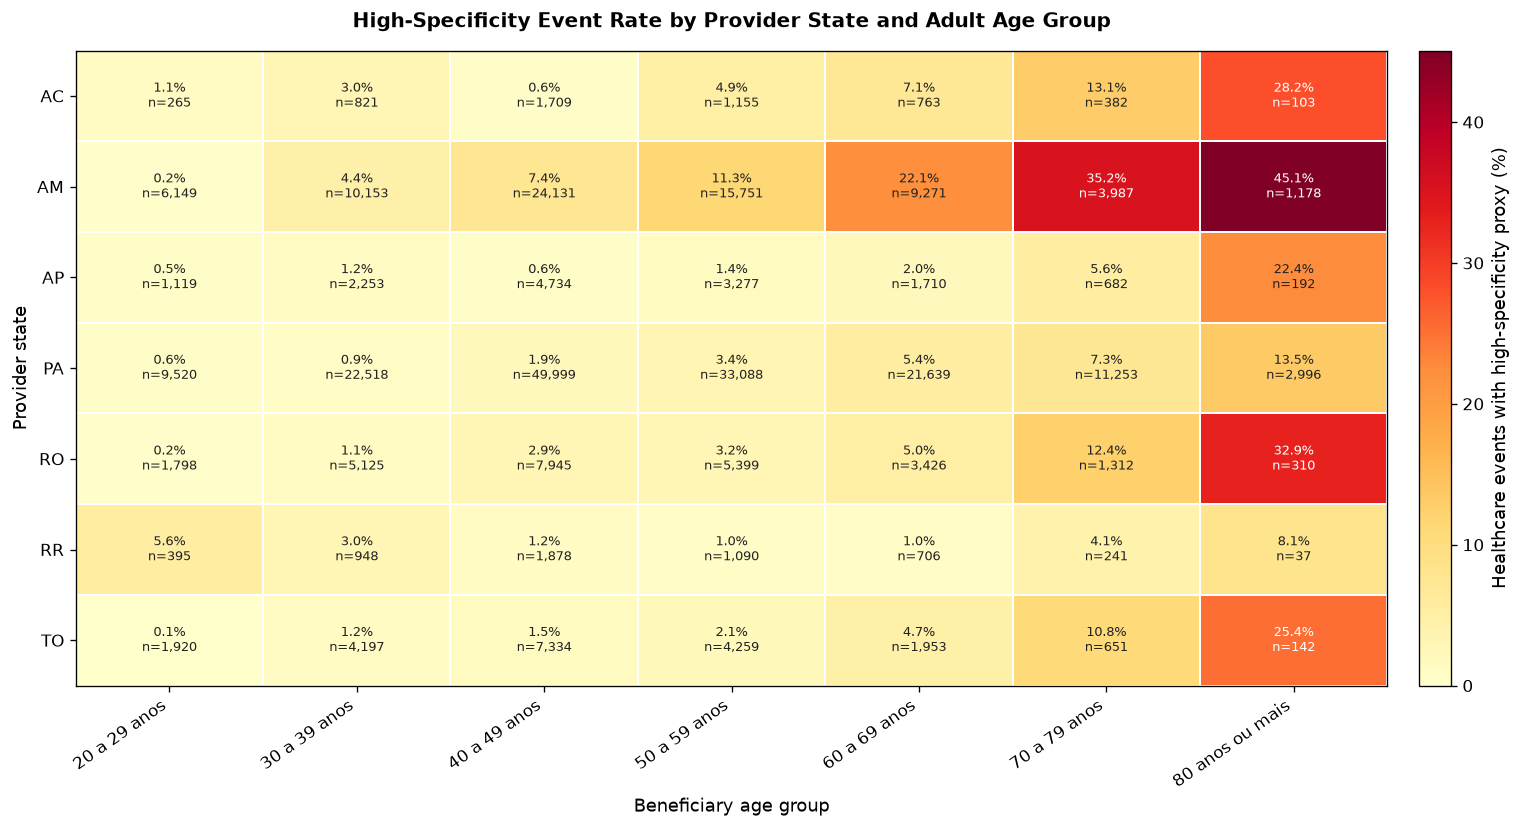

In [9]:
fig, ax = plt.subplots(figsize=(14, 7))
values = np.ma.masked_invalid(proxy_rate.to_numpy(dtype=float))
image = ax.imshow(values, cmap="YlOrRd", aspect="auto", vmin=0)
colorbar = fig.colorbar(image, ax=ax, pad=0.02)
colorbar.set_label("Healthcare events with high-specificity proxy (%)")
ax.set_xticks(np.arange(len(adult_age_order)), labels=adult_age_order, rotation=35, ha="right")
ax.set_yticks(np.arange(len(state_order)), labels=state_order)
ax.set_xlabel("Beneficiary age group")
ax.set_ylabel("Provider state")
ax.set_title("High-Specificity Event Rate by Provider State and Adult Age Group", pad=14)
threshold = np.nanmax(proxy_rate.to_numpy(dtype=float)) * 0.55
for row_index, state in enumerate(state_order):
    for column_index, age_group in enumerate(adult_age_order):
        rate = proxy_rate.loc[state, age_group]
        sample_size = proxy_n.loc[state, age_group]
        if pd.notna(rate) and pd.notna(sample_size):
            color = "white" if rate > threshold else "#222222"
            ax.text(
                column_index, row_index, f"{rate:.1f}%\nn={sample_size:,.0f}",
                ha="center", va="center", fontsize=7.5, color=color,
            )
ax.set_xticks(np.arange(-0.5, len(adult_age_order), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(state_order), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.2)
ax.tick_params(which="minor", bottom=False, left=False)
fig.tight_layout()
plt.show()

### Interpretation rule

The first chi-square test evaluates whether high-specificity event status is associated with adult age group across the region. The age-specific tests then evaluate whether state composition matters within each age group. H3 receives support when the event rate generally increases with age and state differences remain visible within age groups, with effect sizes and denominators large enough to be credible.

**Multiple comparisons.** The state-within-age analysis is not one test but one per adult age bracket, so the seven chi-squares above form a single family and their p-values are adjusted with the Holm step-down procedure rather than read individually. Two caveats govern how much weight that adjustment can carry. First, it is conservative by design and, at this sample size, largely inconsequential: with hundreds of thousands of events the chi-square statistic grows with the denominator, so every stratum clears even the Bonferroni-tightened threshold and the correction changes no conclusion. Second, and for that same reason, significance is not what the hypothesis rests on. The claim in H3 is about the *trend* in effect size across brackets — Cramer's V climbing from 0.101 in the youngest adults to a peak of 0.329 at 70-79, then easing to 0.317 in the smallest bracket, 80+ — and that trend is not something a family-wise error correction can produce or remove. The adjusted p-values are reported so the multiplicity is explicit and auditable; the interpretation continues to be driven by the effect sizes and the size of each stratum, not by the significance flags.

The proxy is derived from billed TUSS codes mapped to SBOC breast-cancer guidelines [2,3]. It is not a diagnosis field. Therefore, the heatmap must not be described as cancer incidence, prevalence, stage distribution, individual treatment eligibility, or the percentage of patients with breast cancer.

## 5. Joint assessment and implications for future modeling

Each hypothesis is judged against the same evidence hierarchy, applied to the
results printed above:

1. **Direction:** Does the observed relationship have the direction proposed by the hypothesis?
2. **Quantitative evidence:** Do the correlation, chi-square departure, rates, and effect sizes consistently support the proposed relationship?
3. **Effect size:** Is the association large enough to matter analytically or operationally?
4. **Robustness:** Does the conclusion remain credible after event-level aggregation, missing-value exclusions, sample-size inspection, and an appropriate non-parametric or categorical test?
5. **Business meaning:** Does the relationship help explain where demand is generated, where it is delivered, or which features should enter the predictive model?

### Verdicts

**H1 — concentration across plans: SUPPORTED.** The top 1% of plans generate
**41.7%** of all unique events, the top 10% generate **84.2%**, and the Gini
coefficient of events per plan is **0.888** — far from the equal-distribution
line. The second half of H1 also holds: within `GRANDE`, the largest size tier,
the mean is 100.8 events per plan against a median of 6.0, and the top 10% of
those plans still hold **88.0%** of the tier's events. Size therefore locates
demand only coarsely, and plan-level ranking is not reducible to it.

**H2 — intermunicipal displacement: SUPPORTED.** Overall **26.8%** of events are
delivered outside the beneficiary's municipality, and the rate is not uniform
across provider states: **33.1% in Tocantins and 31.8% in Pará against 7.1% in
Roraima** — a 26-percentage-point spread. Cramér's V is **0.146**, a small but
non-negligible association (χ² = 6,179.24, df = 6). The direction and the size
of the gaps both match the hypothesis, so residence alone does not determine
where care is delivered.

**H3 — age × geography: SUPPORTED.** The share of events carrying a
high-specificity proxy item rises monotonically across every adult bracket,
from **0.5% (20-29) to 23.2% (80+)**, with Cramér's V = **0.188** for the age
association. The state effect survives within each bracket: all **7 of 7**
stratified tests remain significant after Holm adjustment, and their effect
sizes climb with age, from V = 0.101 at 20-29 to a peak of 0.329 at 70-79,
easing to 0.317 in the smallest bracket, 80+ (n = 4,958). A single common age
effect is therefore not adequate; age and state interact.

**One qualification that applies to all three.** These are associations in
observed billing records. H1 counts events, not patients; H2 records a
municipality difference, not a distance or a formal TFD case; H3 measures an
engineered proxy, not diagnoses. None of the three is weakened by this, but none
should be restated in clinical terms.

### Modeling implications that follow from the three verdicts

- **Plan concentration:** prioritize plan-level modeling and ranking rather than relying on operator size alone; compare model performance and opportunity scores across high- and low-volume plans.
- **Geographic displacement:** model residence and provider geography separately; consider origin-destination features instead of assuming demand remains in the beneficiary's municipality.
- **Age–geography interaction:** compare an explicit age-by-state interaction in a regression with tree-based models that can learn non-additive geographic and demographic patterns. Report performance by state and age group to prevent large segments from hiding weak performance in smaller ones.

### Final limitation

The analysis estimates patterns in observed supplementary-health billing activity. It cannot directly estimate the total population burden of breast cancer, unmet demand, confirmed unique patients, or causality. Any future patient-potential target must define how repeated events and repeated item rows are converted into a valid unit of demand.

## 6. References — Vancouver style

1. Agência Nacional de Saúde Suplementar (ANS). Padrão para Troca de Informação de Saúde Suplementar (TISS) [Internet]. Brasília: ANS; 2026 [cited 2026 Aug 26]. Available from: https://www.gov.br/ans/pt-br/assuntos/prestadores/padrao-para-troca-de-informacao-de-saude-suplementar-2013-tiss
2. Agência Nacional de Saúde Suplementar (ANS). Terminologia Unificada da Saúde Suplementar (TUSS) [Internet]. Brasília: ANS; 2026 [cited 2026 Aug 26]. Available from: https://dadosabertos.ans.gov.br/FTP/PDA/terminologia_unificada_saude_suplementar_TUSS-049/
3. Sociedade Brasileira de Oncologia Clínica (SBOC). Diretrizes SBOC 2025: câncer de mama — estadiamento, neoadjuvante, adjuvante e doença avançada. São Paulo: SBOC; 2025.

### Citation scope

The ANS TISS reference [1] supports the interpretation of the source as an administrative supplementary-health information standard. The ANS TUSS [2] and SBOC [3] references support the crosswalk created upstream and the meaning of the high-specificity proxy received in the processed dataset. Numerical findings in this notebook are calculated directly from the project's processed dataset and should be reported as results of the group analysis rather than attributed to an external publication.